# KMOS Pipeline — Stacked Galaxy Showcase, grouped by galaxy

Same data and stacking as `kmos_stacked_showcase.ipynb` (cells 1–6 identical),
but every galaxy observed in **more than one band** is shown **once**, with all
of its bands combined:

* **Line panels** (Hα · Hβ · [OIII]5007 · [SII]6716) are filled from whichever
  band covers the line — e.g. Hα from YJ and [OIII]/Hβ from IZ of the same
  galaxy, or Hα from H and [OIII]/Hβ from YJ for the z ≈ 1.46 clusters.
  If two bands cover a line, the deeper one (longer exposure) is used.
* **Common centre.**  The aperture of every band is placed at the **Hα position**
  (line peak in the Hα band), transferred to the other cubes via the WCS.  The
  single-band notebook searches each cube for its own Hα peak — in a band
  without Hα (e.g. IZ at z ≈ 0.7) that falls back to the cube centre.
* **Full-spectrum overview**: all bands of the galaxy on one wavelength axis.

**Sections**
1–6. Imports, helpers, load + stack (one stack per galaxy and band), SNRs, ranking
7. Group multi-band galaxies, Hα-based centring of all bands
8. Line-window gallery — one row per galaxy, panels from the matching band
9. Detail view — combined full spectrum, line zooms and maps of all bands

In [1]:
import glob, os, csv, pathlib, warnings, re
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from astropy.io import fits

# ── DATA SOURCE SWITCH ────────────────────────────────────────────────────────
USE_EXTERNAL = True          # True  → use kmos_proc_server_comb/ (external combined cubes)
                              # False → use kmos_ob_proc_server/   (own reduced files)
COMB_BASE    = "kmos_proc_and_comb_server"

# ── paths ─────────────────────────────────────────────────────────────────────
BASE         = "kmos_ob_proc_server"
SUFFIX       = "_s_i_bkg2d_rv_tell.fits"
ECDFS_TABLE  = pathlib.Path("scripts") / "table_ifus_ECDFS 2.fits"
COSMOS_TABLE = pathlib.Path("scripts") / "table_ifus_COSMOS_Field_exptime.fits"

# ── extraction parameters ─────────────────────────────────────────────────────
APERTURE          = 5
EDGE_MARGIN       = 4
MAX_CENTER_OFFSET = 4.0

# ── Hα ───────────────────────────────────────────────────────────────────────
HA_REST      = 0.65628   # µm
SNR_WIN_HALF = 0.0025
SNR_CONT_IN  = 0.006
SNR_CONT_OUT = 0.022
SNR_MIN      = 2.0

# ── display ───────────────────────────────────────────────────────────────────
TOP_DETAIL   = 30          # galaxies in detail view
ZOOM_HALF    = 0.018      # ±µm around each line in zoom panels
HB_ZOOM_HALF = 0.012      # slightly narrower window for Hβ (often weaker)

PALETTE = [
    "#1a6faf", "#c03a2b", "#27ae60", "#8e44ad", "#d35400",
    "#16a085", "#2c3e50", "#e74c3c", "#2980b9", "#1abc9c",
    "#f39c12", "#7f8c8d", "#6c3483", "#1e8449", "#922b21",
    "#0e6655", "#784212", "#1b4f72", "#f1c40f", "#8e44ad",
    "#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#e74c3c",
    "#34495e", "#f39c12", "#2c3e50", "#d35400", "#16a085",
    "#2980b9", "#c0392b", "#27ae60", "#8e44ad", "#f1c40f",
    "#7f8c8d", "#1abc9c", "#e67e22", "#2c3e50", "#3498db",
    "#8e44ad", "#d35400", "#16a085", "#c03a2b", "#27ae60",
    "#922b21", "#1e8449", "#1b4f72", "#784212", "#0e6655",
]

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlepad": 5,
    "axes.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#bbb", "grid.alpha": 0.3, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})

In [2]:
# ── robust line S/N: scripts/line_snr.py ─────────────────────────────────────
import sys, importlib, pathlib
_SCRIPTS = str(pathlib.Path("scripts").resolve())
if _SCRIPTS not in sys.path:
    sys.path.insert(0, _SCRIPTS)
import line_snr as _lsnr
importlib.reload(_lsnr)
import kmos_sample as ks          # galaxy identity, z lookup, exposure time, stacking
importlib.reload(ks)
canonical_field = ks.canonical_field

# ── data helpers ──────────────────────────────────────────────────────────────
def wavelength_axis(hdr):
    cdelt = hdr.get("CDELT3", hdr.get("CD3_3", 1.0))
    return (np.arange(hdr["NAXIS3"]) + 1 - hdr["CRPIX3"]) * cdelt + hdr["CRVAL3"]

def active_ifus(hdul):
    result = []
    for i in range(1, 25):
        try:
            d = hdul[i].data
            if d is not None and np.ndim(d) == 3:
                result.append(i)
        except Exception:
            pass
    return result

def _erode_valid(finite, margin):
    inv = ~finite
    eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:]  |= inv[:-s]
        eroded[:-s] |= inv[s:]
    return ~eroded

def aperture_spectrum(hdul, ifu, center, box=APERTURE, margin=EDGE_MARGIN):
    cube  = np.array(hdul[ifu].data)
    hdr   = hdul[ifu].header
    py, px = center
    h2    = box // 2
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch  = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid  = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(cube.shape[0], np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return wavelength_axis(hdr), spec

def ifu_center(cube):
    return (cube.shape[1] // 2, cube.shape[2] // 2)

def find_exposures(base=BASE, suffix=SUFFIX):
    result = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(base, "*", "science", f"*{suffix}"))):
        parts = path.replace("\\", "/").split("/")
        ob    = parts[-3]
        with fits.open(path) as h:
            band = h[0].header.get("HIERARCH ESO INS GRAT1 ID", "??")
        result[(ob, band)].append(path)
    return dict(result)

def ob_to_dpid(ob_name):
    """Convert OB folder name to dp_id format.
    'KMOS.2026-01-13T03-42-28.829' → 'KMOS.2026-01-13T03:42:28.829'
    """
    if 'T' not in ob_name:
        return ob_name
    date_part, time_part = ob_name.split('T', 1)
    parts = time_part.split('-', 2)
    if len(parts) == 3:
        return f"{date_part}T{parts[0]}:{parts[1]}:{parts[2]}"
    return ob_name

def ha_peak_center(cube, wave, z, margin=EDGE_MARGIN, min_nbr=0.08):
    ha_obs = HA_REST * (1.0 + z)
    hp     = int(np.argmin(np.abs(wave - ha_obs)))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid  = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    ha_im  = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx = ha_im.shape
    flat   = ha_im.ravel()
    order  = np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]
    for idx in order:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [ha_im[py+dy, px+dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px), ha_im
    return ifu_center(cube), ha_im

def line_snr(wave, spec, z, line_rest,
             win_half=SNR_WIN_HALF, cont_in=SNR_CONT_IN, cont_out=SNR_CONT_OUT,
             min_width_px=3):
    """Robust S/N via scripts/line_snr.py: Gaussian-fit line flux / error
    (spikes masked, LSF/velocity priors, correlated noise; see that file)."""
    return _lsnr.line_snr(wave, spec, z, line_rest, win_half=win_half,
                          cont_in=cont_in, cont_out=cont_out)

def ha_snr(wave, spec, z):
    return line_snr(wave, spec, z, HA_REST)

def narrowband_image(cube, wave, z, line_rest, margin=EDGE_MARGIN):
    lam_obs = line_rest * (1.0 + z)
    if not (wave.min() < lam_obs < wave.max()):
        return None
    hp      = int(np.argmin(np.abs(wave - lam_obs)))
    p0, p1  = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid   = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    return np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)

# ── emission lines ────────────────────────────────────────────────────────────
EMISSION_LINES = {
    "[OII]3727":    (0.37270, "#e377c2"),
    "Hβ":           (0.48627, "#1f77b4"),
    "[OIII]4959":   (0.49594, "#7fdbff"),
    "[OIII]5007":   (0.50082, "#17becf"),
    "Hα":           (0.65628, "#d62728"),
    "[NII]6583":    (0.65835, "#ff7f0e"),
    "[SII]6716":    (0.67163, "#9467bd"),
    "[SII]6731":    (0.67308, "#c5b0d8"),
}

# ── redshift catalogue ────────────────────────────────────────────────────────
_Z_TABLE, _Z_TYPE, _Z_QUALITY = {}, {}, {}
_Z_CSV = pathlib.Path("scripts") / "target_redshifts.csv"
if _Z_CSV.exists():
    with open(_Z_CSV, newline="", encoding="utf-8") as _f:
        for _row in csv.DictReader(_f):
            if (_row.get("redshift") or "").strip():
                _key = (_row["field"].strip(), _row["arm_target_id"].strip())
                _Z_TABLE[_key] = float(_row["redshift"].strip())
                _Z_TYPE[_key]  = (_row.get("redshift_type") or "").strip()
                _q = (_row.get("quality") or "").strip()
                try:
                    _Z_QUALITY[_key] = float(_q)
                except (ValueError, TypeError):
                    _Z_QUALITY[_key] = np.nan
    print(f"Loaded {len(_Z_TABLE)} redshifts  "
          f"(spec: {sum(1 for v in _Z_TYPE.values() if v=='spec')}, "
          f"photo: {sum(1 for v in _Z_TYPE.values() if v=='photo')}, "
          f"cluster: {sum(1 for v in _Z_TYPE.values() if v=='cluster')})")
else:
    print(f"WARNING: {_Z_CSV} not found — emission lines will not be drawn")

# galaxy-level redshift lookup: exact (target list, id), else (survey region, id)
# — e.g. 'SPT2040_Halpha' is not in the CSV but its galaxies are.  scripts/kmos_sample.py
ZCAT = ks.RedshiftCatalog(_Z_CSV)
z_lookup = ZCAT.lookup
print(f"  → {len(ZCAT)} unique galaxies (survey region, target id) with a redshift")

def get_z_meta(hdul, ifu):
    hdr0  = hdul[0].header
    field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
    key   = f"ESO OCS ARM{ifu} NAME"
    tid   = str(hdr0.get(key) or hdr0.get(f"HIERARCH {key}") or "").strip()
    if not field or not tid:
        return None, "", np.nan
    zi = z_lookup(field, tid)
    return zi if zi is not None else (None, "", np.nan)

Loaded 178 redshifts  (spec: 161, photo: 1, cluster: 16)
  → 158 unique galaxies (survey region, target id) with a redshift


In [3]:
# ── Load FITS catalog tables → group_id lookup ─────────────────────────────────
# dpid_ifu_to_group[(dp_id, ifu)] = group_id
dpid_ifu_to_group = {}

for tbl_path in [ECDFS_TABLE, COSMOS_TABLE]:
    if not tbl_path.exists():
        print(f"WARNING: {tbl_path} not found")
        continue
    with fits.open(tbl_path) as hdul:
        t = hdul[1].data
        for i in range(len(t)):
            dpid_ifu_to_group[(t['dp_id'][i].strip(), int(t['ifu'][i]))] = int(t['group_id'][i])
    print(f"Loaded {len(t):,} rows from {tbl_path.name}")

print(f"Total catalog entries from tables: {len(dpid_ifu_to_group):,}")

# ── Fallback: build synthetic group_ids for fields not in the FITS tables ──────
# Fields like SPT2040 and XMM2215 have no ECDFS/COSMOS catalog table; assign
# synthetic group_ids (≥ 90000) from (field, arm_target_id) pairs found in Z_TABLE.
_synthetic_next = 90000
_field_tid_to_group = {}   # (field, arm_target_id) → synthetic group_id

for path in sorted(glob.glob(os.path.join(BASE, "*", "science", f"*{SUFFIX}"))):
    parts = path.replace("\\", "/").split("/")
    ob    = parts[-3]
    dpid  = ob_to_dpid(ob)
    with fits.open(path) as h:
        hdr0  = h[0].header
        field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
        if not field:
            continue
        for ifu in range(1, 25):
            if (dpid, ifu) in dpid_ifu_to_group:
                continue           # already covered by tables
            if ifu >= len(h):
                continue
            try:
                d = h[ifu].data
                if d is None or np.ndim(d) != 3:
                    continue
            except Exception:
                continue
            key_hdr = f"ESO OCS ARM{ifu} NAME"
            tid = str(hdr0.get(key_hdr) or hdr0.get(f"HIERARCH {key_hdr}") or "").strip()
            if not tid:
                continue
            k = (field, tid)
            if k not in _Z_TABLE:
                continue           # unknown target, skip
            if k not in _field_tid_to_group:
                _field_tid_to_group[k] = _synthetic_next
                _synthetic_next += 1
            dpid_ifu_to_group[(dpid, ifu)] = _field_tid_to_group[k]

if _field_tid_to_group:
    print(f"Added {len(_field_tid_to_group)} synthetic group_ids for targets not in catalog tables "
          f"(ids {90000}–{_synthetic_next - 1})")
    from collections import Counter
    field_counts = Counter(k[0] for k in _field_tid_to_group)
    for field, n in field_counts.most_common():
        print(f"  {field}: {n} targets")

print(f"Total catalog entries (incl. synthetic): {len(dpid_ifu_to_group):,}")

# Reverse map for diagnostics
group_to_dpids = defaultdict(list)
for (dpid, ifu), gid in dpid_ifu_to_group.items():
    group_to_dpids[gid].append((dpid, ifu))
print(f"Unique group_ids: {len(group_to_dpids):,}")

Loaded 147,261 rows from table_ifus_ECDFS 2.fits


Loaded 119,729 rows from table_ifus_COSMOS_Field_exptime.fits
Total catalog entries from tables: 266,990
Total catalog entries (incl. synthetic): 266,990
Unique group_ids: 2,189


In [4]:
# ── Load all IFUs and stack by group_id ────────────────────────────────────────
print("Scanning exposures and grouping by group_id …")

# group_data[(group_id, band)] collects everything for one galaxy+band stack
group_data = defaultdict(lambda: dict(
    spectra=[], obs=set(), wave=None,
    z=None, z_type='', z_quality=np.nan,
    cube=None, ha_image=None,
    ctr_ha=None, ctr_geom=None, fallback=False,
    _best_ha_snr=-np.inf,
))

if USE_EXTERNAL:
    # ── combined cubes → one stack per (galaxy, band); see scripts/kmos_sample.py
    #    galaxy = (survey region, target id) across all target lists; z looked up
    #    per galaxy; on-source time = NCOMBINE × DIT (EXPTIME is 1.5× too short);
    #    cubes of one galaxy+band aligned on the sky and stacked by exposure time
    _stacks = ks.load_galaxy_band_stacks(COMB_BASE, ZCAT, normalise=False)
    _ext_gid_map = {(_st['field'], _st['tid']): _st['gid'] for _st in _stacks}
    for _st in _stacks:
        _cube, _wave, _z = _st['cube'].astype(float), _st['wave'], _st['z']
        _ctr_geo = ifu_center(_cube)
        _ctr_raw, _ha_im = ha_peak_center(_cube, _wave, _z)
        _off  = np.hypot(_ctr_raw[0] - _ctr_geo[0], _ctr_raw[1] - _ctr_geo[1])
        _fb   = _off > MAX_CENTER_OFFSET
        _ctr  = _ctr_geo if _fb else _ctr_raw

        _h2 = APERTURE // 2; _py, _px = _ctr
        _y0, _y1 = max(_py - _h2, 0), min(_py + _h2 + 1, _cube.shape[1])
        _x0, _x1 = max(_px - _h2, 0), min(_px + _h2 + 1, _cube.shape[2])
        _patch = _cube[:, _y0:_y1, _x0:_x1].reshape(_cube.shape[0], -1)
        _valid = _erode_valid(np.isfinite(_patch), EDGE_MARGIN)
        _clean = np.where(_valid, _patch, np.nan)
        _spec  = np.full(_cube.shape[0], np.nan)
        _ok    = _valid.any(axis=1)
        _spec[_ok] = np.nansum(_clean[_ok], axis=1)
        _ref = np.nanmedian(_spec)
        if np.isfinite(_ref) and _ref != 0: _spec = _spec / _ref

        g = group_data[(_st['gid'], _st['band'])]
        g.update(wave=_wave, z=_z, z_type=_st['z_type'], z_quality=_st['z_quality'],
                 cube=_cube, ha_image=_ha_im, ctr_ha=_ctr, ctr_geom=_ctr_geo,
                 fallback=_fb, field=_st['field'], tid=_st['tid'],
                 n_cubes=_st['n_cubes'], exptime_s=_st['exptime_s'],
                 target_lists=_st['target_lists'])
        g['spectra'].append(_spec)
        g['obs'] = set(_st['folders'])

    print(f"External mode: {len(group_data)} (galaxy, band) stacks of "
          f"{len({k[0] for k in group_data})} galaxies from {COMB_BASE}/")

else:
    # ── Load from kmos_ob_proc_server/ (normal mode) ──────────────────────────
    exposures = find_exposures()
    n_matched = 0
    n_skipped = 0

    for (ob, band), paths in sorted(exposures.items()):
        dpid = ob_to_dpid(ob)

        ifu_set = set()
        for p in paths:
            with fits.open(p) as h:
                ifu_set.update(active_ifus(h))

        for ifu in sorted(ifu_set):
            group_id = dpid_ifu_to_group.get((dpid, ifu))
            if group_id is None:
                n_skipped += 1
                continue
            n_matched += 1
            key = (group_id, band)
            g   = group_data[key]

            spectra_this_ob = []
            wave_this_ob    = None
            cube_data       = None
            ctr_geom        = None
            ctr_ha          = None
            ha_image        = None
            fallback        = False

            for p in paths:
                with fits.open(p) as h:
                    if ifu not in active_ifus(h):
                        continue
                    cube = np.array(h[ifu].data)

                    if wave_this_ob is None:
                        wave_this_ob = wavelength_axis(h[ifu].header)
                        cube_data    = cube
                        ctr_geom     = ifu_center(cube)

                        if g['z'] is None:
                            z, z_type, z_quality = get_z_meta(h, ifu)
                            if z is not None:
                                g.update(z=z, z_type=z_type, z_quality=z_quality)

                        z = g['z']
                        if z is not None:
                            ctr_raw, ha_image = ha_peak_center(cube, wave_this_ob, z)
                            offset = np.hypot(ctr_raw[0] - ctr_geom[0],
                                              ctr_raw[1] - ctr_geom[1])
                            if offset > MAX_CENTER_OFFSET:
                                ctr_ha   = ctr_geom
                                fallback = True
                            else:
                                ctr_ha = ctr_raw
                        else:
                            ctr_ha = ctr_geom

                    ctr = ctr_ha if ctr_ha is not None else ifu_center(cube)
                    _, s = aperture_spectrum(h, ifu, ctr)
                    s_ref = np.nanmedian(s)
                    if np.isfinite(s_ref) and s_ref != 0:
                        s = s / s_ref
                    spectra_this_ob.append(s)

            if not spectra_this_ob or wave_this_ob is None:
                continue

            if g['wave'] is None:
                g['wave'] = wave_this_ob

            z = g['z']
            if z is not None and cube_data is not None:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    med_ob = np.nanmedian(np.vstack(spectra_this_ob), axis=0)
                snr_ob = ha_snr(g['wave'], med_ob, z)
                if np.isfinite(snr_ob) and snr_ob > g['_best_ha_snr']:
                    g.update(
                        _best_ha_snr=snr_ob,
                        cube=cube_data, ha_image=ha_image,
                        ctr_ha=ctr_ha, ctr_geom=ctr_geom,
                        fallback=fallback,
                    )

            g['spectra'].extend(spectra_this_ob)
            g['obs'].add(ob)

    print(f"  IFU×OB matched to catalog:  {n_matched}")
    print(f"  IFU×OB not in catalog:      {n_skipped}")
    print(f"  Unique (group_id, band) stacks: {len(group_data)}")

Scanning exposures and grouping by group_id …


kmos_proc_and_comb_server: 280 combined cubes, 7 without redshift ['cosmos_0.6_0.8_h21.4.cat/recenter1', 'cosmos_0.6_0.8_h21.4.cat/recenter2', 'cosmos_0.6_0.8_h21.7.cat/recenter5', 'cosmos_0.6_0.8_h21.7.cat/recenter6', 'cosmos_0.6_0.8_h21.7.cat/recenter7']
  → 158 galaxies, 253 (galaxy, band) stacks, 20 stacked from >1 cube   CDFS: 37  COSMOS: 80  SPT2040: 21  XMM2215: 20


External mode: 253 (galaxy, band) stacks of 158 galaxies from kmos_proc_and_comb_server/


In [5]:
# ── Build final stacked entries and compute SNRs ────────────────────────────────
LINE_DEFS = {
    'ha':   (HA_REST,  SNR_WIN_HALF, SNR_CONT_IN, SNR_CONT_OUT),
    'hb':   (0.48627,  0.0020, 0.005, 0.018),
    'oiii': (0.50082,  0.0020, 0.005, 0.018),
    'sii':  (0.67163,  0.0020, 0.005, 0.018),
}

all_stacked = []
_skipped_no_z = []

for (group_id, band), g in group_data.items():
    if not g['spectra'] or g['wave'] is None:
        continue
    if g.get('z') is None:
        _skipped_no_z.append((group_id, band, len(g['obs']), len(g['spectra'])))
        continue
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        med = np.nanmedian(np.vstack(g['spectra']), axis=0)

    snrs = {}
    for lkey, (lrest, wh, ci, co) in LINE_DEFS.items():
        snrs[lkey] = line_snr(g['wave'], med, g['z'], lrest,
                              win_half=wh, cont_in=ci, cont_out=co)

    all_stacked.append(dict(
        group_id  = group_id,
        field     = g.get('field', '?'),
        tid       = str(g.get('tid', '')),
        exptime_s = g.get('exptime_s', np.nan),
        band      = band,
        z         = g['z'],
        z_type    = g['z_type'],
        z_quality = g['z_quality'],
        wave      = g['wave'],
        spectra   = g['spectra'],
        med       = med,
        n_obs     = len(g['obs']),
        n_exp     = g.get('n_cubes', len(g['spectra'])),
        cube      = g.get('cube'),
        ha_image  = g.get('ha_image'),
        ctr_ha    = g.get('ctr_ha'),
        ctr_geom  = g.get('ctr_geom'),
        fallback  = g.get('fallback', False),
        **{f'snr_{k}': v for k, v in snrs.items()},
    ))

# Sort by Hα SNR (NaN last)
all_stacked.sort(
    key=lambda x: x['snr_ha'] if np.isfinite(x.get('snr_ha', np.nan)) else -np.inf,
    reverse=True
)

# One entry per galaxy for Hα: if Hα is covered in two bands (IZ and YJ at
# z < 0.66) the deeper band is used — chosen by exposure time, never by SNR.
_ha_pick = {}
for e in all_stacked:
    if e['wave'].min() < HA_REST * (1.0 + e['z']) < e['wave'].max():
        b = _ha_pick.get(e['group_id'])
        if b is None or e.get('exptime_s', 0) > b.get('exptime_s', 0):
            _ha_pick[e['group_id']] = e
for e in all_stacked:
    e['ha_primary'] = _ha_pick.get(e['group_id']) is e

def _n_gal(key):
    """Unique galaxies with SNR ≥ SNR_MIN in this line (any band)."""
    return len({e['group_id'] for e in all_stacked
                if np.isfinite(e.get(key, np.nan)) and e[key] >= SNR_MIN
                and (key != 'snr_ha' or e['ha_primary'])})
n_ha, n_hb, n_oi, n_si = _n_gal('snr_ha'), _n_gal('snr_hb'), _n_gal('snr_oiii'), _n_gal('snr_sii')
print(f"(galaxy, band) stacks: {len(all_stacked)}   unique galaxies: "
      f"{len({e['group_id'] for e in all_stacked})}   (counts below = galaxies)")
print(f"  Hα   SNR ≥ {SNR_MIN}: {n_ha}")
print(f"  Hβ   SNR ≥ {SNR_MIN}: {n_hb}")
print(f"  [OIII] SNR ≥ {SNR_MIN}: {n_oi}")
print(f"  [SII]  SNR ≥ {SNR_MIN}: {n_si}")

# ── DIAGNOSTIC: full listing by n_obs ─────────────────────────────────────────
print(f"\nAll {len(all_stacked)} stacked entries (sorted by n_obs):")
print(f"{'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'z':>7}  {'z_type':>7}  {'n_obs':>5}  "
      f"{'Hα':>6}  {'Hβ':>6}  {'[OIII]':>7}  {'[SII]':>6}  {'fb':>4}")
print("-" * 72)
def _f(v): return f"{v:.1f}" if np.isfinite(v) else "NaN"
for e in sorted(all_stacked, key=lambda x: x['n_obs'], reverse=True):
    print(f"{e['group_id']:>6}  {e['field']:8} {e['tid']:>8}  {e['band']:5}  {e['z']:>7.4f}  {e.get('z_type','?'):>7}  "
          f"{e['n_obs']:>5}  {_f(e['snr_ha']):>6}  {_f(e['snr_hb']):>6}  "
          f"{_f(e['snr_oiii']):>7}  {_f(e['snr_sii']):>6}  "
          f"{'YES' if e.get('fallback') else '':>4}")

if _skipped_no_z:
    print(f"\n⚠ Skipped — no redshift in CSV ({len(_skipped_no_z)} entries):")
    print(f"{'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'n_obs':>5}  {'n_exp':>5}")
    for gid, band, nobs, nexp in sorted(_skipped_no_z, key=lambda x: x[2], reverse=True):
        print(f"{gid:>6}  {band:5}  {nobs:>5}  {nexp:>5}")

(galaxy, band) stacks: 253   unique galaxies: 158   (counts below = galaxies)
  Hα   SNR ≥ 2.0: 73
  Hβ   SNR ≥ 2.0: 45
  [OIII] SNR ≥ 2.0: 57
  [SII]  SNR ≥ 2.0: 49

All 253 stacked entries (sorted by n_obs):
   gid  field         tid  band         z   z_type  n_obs      Hα      Hβ   [OIII]   [SII]    fb
------------------------------------------------------------------------
 90065  COSMOS       2944  YJ      0.7303     spec      2    30.4     NaN      NaN     7.5   YES
 90084  COSMOS       3671  YJ      0.7297     spec      2     3.0     NaN      NaN    -4.0   YES
 90071  COSMOS       3055  YJ      0.7259     spec      2     2.3     NaN      NaN     2.4   YES
 90080  COSMOS       3638  YJ      0.7324     spec      2     2.1     NaN      NaN     4.1   YES
 90072  COSMOS       3059  YJ      0.6980     spec      2     2.0     NaN      NaN     1.0   YES
 90073  COSMOS       3092  YJ      0.7374     spec      2     1.9     NaN      NaN     3.1   YES
 90075  COSMOS       3162  YJ      0.7

In [6]:
# ── Ranking table ─────────────────────────────────────────────────────────────
def _fmt(v):
    return f"{v:.1f}" if np.isfinite(v) else "—"

print(f"{'#':>3}  {'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'z':>7}  {'type':>7}  {'q':>3}  "
      f"{'N_obs':>5}  {'N_exp':>5}  {'Hα':>6}  {'Hβ':>6}  {'[OIII]':>7}  {'[SII]':>6}")
print("-" * 88)
_spec_stacked = [e for e in all_stacked if e.get("z_type") in ("spec", "cluster")]
for i, e in enumerate(_spec_stacked):
    q_s = f"{e['z_quality']:.0f}" if np.isfinite(e.get('z_quality', np.nan)) else "—"
    print(f"{i+1:>3}  {e['group_id']:>6}  {e['field']:8} {e['tid']:>8}  {e['band']:5}  {e['z']:>7.4f}  "
          f"{e['z_type']:>7}  {q_s:>3}  "
          f"{e['n_obs']:>5}  {e['n_exp']:>5}  "
          f"{_fmt(e['snr_ha']):>6}  {_fmt(e['snr_hb']):>6}  "
          f"{_fmt(e['snr_oiii']):>7}  {_fmt(e['snr_sii']):>6}")

  #     gid  field         tid  band         z     type    q  N_obs  N_exp      Hα      Hβ   [OIII]   [SII]
----------------------------------------------------------------------------------------
  1   90107  COSMOS      97505  YJ      0.6613     spec    4      1      1    76.4       —        —     5.3
  2   90097  COSMOS      92754  YJ      0.6263     spec    4      1      1    72.7       —        —    14.7
  3   90091  COSMOS      90874  YJ      0.6629     spec    4      1      1    44.2       —        —     1.7
  4   90020  CDFS        23420  IZ      0.6050     spec    —      1      1    39.2       —     13.8    10.3
  5   90053  COSMOS    1168518  YJ      0.7368     spec    4      1      1    37.1       —        —     9.9
  6   90145  XMM2215     31179  H       1.4502     spec    —      1      1    33.5       —        —     8.8
  7   90065  COSMOS       2944  YJ      0.7303     spec    4      2      2    30.4       —        —     7.5
  8   90150  XMM2215     32400  H       1.4540 

## Group multi-band galaxies — one entry per galaxy, all bands centred on Hα

In [7]:
# ── Group the (galaxy, band) stacks by galaxy; centre all bands on Hα ──────────
ZOOM_PANELS = [
    ('ha', HA_REST, r'H$\alpha$', '#d62728', ZOOM_HALF,
     [('[NII]6548', 0.65480, '#ff7f0e', 0.8, ':'), ('[NII]6583', 0.65835, '#ff7f0e', 1.1, '--')]),
    ('hb', 0.48627, r'H$\beta$', '#1f77b4', HB_ZOOM_HALF,
     [('[OIII]4959', 0.49594, '#7fdbff', 0.8, ':')]),
    ('oiii', 0.50082, r'[OIII]$\lambda$5007', '#17becf', ZOOM_HALF,
     [('[OIII]4959', 0.49594, '#7fdbff', 0.8, ':'), (r'H$\beta$', 0.48627, '#1f77b4', 0.8, '--')]),
    ('sii', 0.67163, r'[SII]$\lambda$6716', '#9467bd', ZOOM_HALF,
     [(r'H$\alpha$', HA_REST, '#d62728', 1.2, '--'), ('[NII]6583', 0.65835, '#ff7f0e', 0.9, ':'),
      ('[SII]6731', 0.67308, '#c5b0d8', 0.9, ':')]),
]
BAND_COLORS = {'IZ': '#1a6faf', 'YJ': '#27ae60', 'H': '#c03a2b', 'HK': '#8e44ad', 'K': '#d35400'}

_wcs_of = {(_st['gid'], _st['band']): _st['wcs'] for _st in _stacks}

def _covers(e, lrest):
    return e['wave'].min() < lrest * (1.0 + e['z']) < e['wave'].max()

def _fin(v, default=-np.inf):
    return v if (v is not None and np.isfinite(v)) else default

def extract_spec(cube, ctr):
    """Same 5×5 box, edge erosion and median normalisation as the loading cell."""
    h2 = APERTURE // 2; py, px = ctr
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid = _erode_valid(np.isfinite(patch), EDGE_MARGIN)
    clean = np.where(valid, patch, np.nan)
    spec  = np.full(cube.shape[0], np.nan)
    ok    = valid.any(axis=1)
    spec[ok] = np.nansum(clean[ok], axis=1)
    ref = np.nanmedian(spec)
    return spec / ref if (np.isfinite(ref) and ref != 0) else spec

def _line_snrs(wave, spec, z):
    return {k: line_snr(wave, spec, z, lrest, win_half=wh, cont_in=ci, cont_out=co)
            for k, (lrest, wh, ci, co) in LINE_DEFS.items()}

_by_gal = defaultdict(list)
for e in all_stacked:
    _by_gal[e['group_id']].append(e)

gal_groups = []
for gid, ents in _by_gal.items():
    if len({e['band'] for e in ents}) < 2:
        continue
    ents = sorted(ents, key=lambda e: ks.band_rank(e['band']))
    ha_ents = [e for e in ents if _covers(e, HA_REST)]
    ref = (max(ha_ents, key=lambda e: e.get('exptime_s', 0)) if ha_ents
           else max(ents, key=lambda e: max(_fin(e.get(f'snr_{k}')) for k in LINE_DEFS)))
    ref_wcs = _wcs_of.get((gid, ref['band']))

    members = []
    for e in ents:
        m = dict(e)
        m['ctr_src'] = f"own {e['band']} peak" + (" [fb]" if e.get('fallback') else "")
        if e is not ref and ref_wcs is not None and not ref.get('fallback'):
            cy, cx = ref['ctr_ha']
            ra, dec = ref_wcs.pixel_to_world_values(cx, cy)
            px, py = _wcs_of[(gid, e['band'])].world_to_pixel_values(ra, dec)
            iy, ix = int(round(float(py))), int(round(float(px)))
            ny, nx = e['cube'].shape[1:]
            if 0 <= iy < ny and 0 <= ix < nx:
                spec = extract_spec(e['cube'], (iy, ix))
                m.update(ctr_ha=(iy, ix), med=spec, spectra=[spec], fallback=False,
                         ctr_src=f"Hα position from {ref['band']} (WCS)",
                         **{f'snr_{k}': v for k, v in _line_snrs(e['wave'], spec, e['z']).items()})
        if e is ref:
            m['ctr_src'] = f"Hα peak ({e['band']})" if _covers(e, HA_REST) else m['ctr_src']
        members.append(m)

    use = {}
    for lkey, lrest, *_ in ZOOM_PANELS:
        cands = [m for m in members if _covers(m, lrest)]
        use[lkey] = max(cands, key=lambda m: m.get('exptime_s', 0)) if cands else None

    snr = {k: (use[k][f'snr_{k}'] if use[k] is not None else np.nan) for k in use}
    gal_groups.append(dict(
        group_id=gid, field=ents[0]['field'], tid=ents[0]['tid'],
        z=ents[0]['z'], z_type=ents[0]['z_type'],
        members=members, ref=ref, use=use, snr=snr,
        best=max(_fin(v) for v in snr.values()),
    ))

gal_groups.sort(key=lambda g: (_fin(g['snr']['ha']), g['best']), reverse=True)

print(f"Galaxies with >1 band: {len(gal_groups)}")
for f in sorted({g['field'] for g in gal_groups}):
    sub = [g for g in gal_groups if g['field'] == f]
    print(f"  {f:8s} {len(sub):3d}   bands: "
          + ", ".join(sorted({'+'.join(m['band'] for m in g['members']) for g in sub})))
print()
print(f"{'#':>3}  {'field':8} {'tid':>8}  {'z':>7}  " +
      "  ".join(f"{k:>12}" for k, *_ in ZOOM_PANELS) + "   (SNR · band used)")
print("-" * 92)
def _cell(g, k):
    u = g['use'][k]
    return f"{g['snr'][k]:6.1f} · {u['band']:<3}" if (u is not None and np.isfinite(g['snr'][k])) else f"{'—':>12}"
for i, g in enumerate(gal_groups):
    print(f"{i+1:>3}  {g['field']:8} {g['tid']:>8}  {g['z']:>7.4f}  " +
          "  ".join(f"{_cell(g, k):>12}" for k, *_ in ZOOM_PANELS))

Galaxies with >1 band: 95
  COSMOS    54   bands: IZ+YJ
  SPT2040   21   bands: YJ+H
  XMM2215   20   bands: YJ+H

  #  field         tid        z            ha            hb          oiii           sii   (SNR · band used)
--------------------------------------------------------------------------------------------
  1  COSMOS      97505   0.6613    76.4 · YJ      2.9 · IZ      0.9 · IZ      5.3 · YJ 
  2  COSMOS      90874   0.6629    44.2 · YJ      1.6 · IZ      2.0 · IZ      1.7 · YJ 
  3  COSMOS    1168518   0.7368    37.1 · YJ      1.3 · IZ      1.0 · IZ      9.9 · YJ 
  4  XMM2215     31179   1.4502    33.5 · H       9.3 · YJ     11.0 · YJ      8.8 · H  
  5  COSMOS       2944   0.7303    30.4 · YJ      1.1 · IZ      0.8 · IZ      7.5 · YJ 
  6  XMM2215     32400   1.4540    28.0 · H       2.3 · YJ      6.3 · YJ      3.0 · H  
  7  XMM2215     32650   1.4610    27.3 · H       4.2 · YJ      8.6 · YJ      4.3 · H  
  8  COSMOS      92754   0.6263    25.1 · IZ      1.4 · IZ      2.0 

## Line-window gallery — one row per galaxy

Each panel shows the line from the band that covers it (band tag top-left).  Only galaxies with at least one line at SNR ≥ `SNR_MIN`.

In [8]:
show = [g for g in gal_groups if g['z_type'] in ('spec', 'cluster') and g['best'] >= SNR_MIN]

if not show:
    print(f"No multi-band galaxies with a line at SNR ≥ {SNR_MIN}.")
else:
    ncols, nrows = len(ZOOM_PANELS), len(show)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.8, nrows * 2.8),
                             constrained_layout=True)
    if nrows == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle(
        f"KMOS multi-band galaxies — Line Windows from the matching band  "
        f"({nrows} galaxies with a line at SNR ≥ {SNR_MIN}, spec/cluster z)",
        fontsize=12, fontweight='bold', y=1.002,
    )
    for ci, (_, _, label, lc, _, _) in enumerate(ZOOM_PANELS):
        axes[0, ci].set_title(label, fontsize=10, fontweight='bold', color=lc, pad=8)

    for ri, (g, color) in enumerate(zip(show, PALETTE * 10)):
        z = g['z']
        for ci, (lkey, lrest, label, lc, zhalf, companions) in enumerate(ZOOM_PANELS):
            ax  = axes[ri, ci]
            m   = g['use'][lkey]
            lam = lrest * (1.0 + z)
            wlo, whi = lam - zhalf, lam + zhalf
            ax.set_xlim(wlo * 1e4, whi * 1e4)
            ax.tick_params(labelsize=6)
            if ri < nrows - 1:
                ax.set_xticklabels([])
            if m is None:
                ax.text(0.5, 0.5, 'not covered by any band', ha='center', va='center',
                        transform=ax.transAxes, fontsize=8, color='#aaa', style='italic')
            else:
                wave = m['wave']
                mask = (wave >= wlo) & (wave <= whi)
                ax.plot(wave[mask] * 1e4, m['med'][mask], color=color, lw=1.8, zorder=3)
                ax.axvline(lam * 1e4, color=lc, lw=1.3, ls='--', alpha=0.85, zorder=2)
                ax.text(lam * 1e4, 0.97, label, transform=ax.get_xaxis_transform(),
                        rotation=90, ha='right', va='top', fontsize=6, color=lc,
                        bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
                for cname, crest, clc, clw, cls in companions:
                    co = crest * (1.0 + z)
                    if wlo <= co <= whi:
                        ax.axvline(co * 1e4, color=clc, lw=clw, ls=cls, alpha=0.75, zorder=2)
                        ax.text(co * 1e4, 0.97, cname, transform=ax.get_xaxis_transform(),
                                rotation=90, ha='right', va='top', fontsize=5.5, color=clc,
                                bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
                fv = m['med'][mask]; fv = fv[np.isfinite(fv)]
                if fv.size:
                    ylo, yhi = np.nanpercentile(fv, 2), np.nanpercentile(fv, 99)
                    pad = 0.18 * max(yhi - ylo, 0)
                    ax.set_ylim(ylo - pad, yhi + pad)
                snr_v = m.get(f'snr_{lkey}', np.nan)
                ax.text(0.98, 0.96, (f"SNR={snr_v:.1f}" if np.isfinite(snr_v) else "SNR=—"),
                        transform=ax.transAxes, ha='right', va='top', fontsize=6.5, color='#333',
                        bbox=dict(fc='white', ec='none', alpha=0.7, pad=1))
                ax.text(0.02, 0.96, m['band'], transform=ax.transAxes, ha='left', va='top',
                        fontsize=7, fontweight='bold', color=BAND_COLORS.get(m['band'], '#333'),
                        bbox=dict(fc='white', ec='none', alpha=0.7, pad=1))
            if ci == 0:
                times = "  ".join(f"{mm['band']} {mm.get('exptime_s', np.nan)/3600:.1f} h"
                                  for mm in g['members'])
                ax.set_ylabel(f"{g['field']} {g['tid']}  z={z:.4f} [{g['z_type']}]\n{times}",
                              fontsize=7, labelpad=4)
        if ri == nrows - 1:
            for ci in range(ncols):
                axes[ri, ci].set_xlabel(r'$\lambda_{\rm obs}$  (Å)', fontsize=7)

    plt.savefig('kmos_stacked_group_gallery.pdf', bbox_inches='tight')
    plt.show()
    print('Saved → kmos_stacked_group_gallery.pdf')

Saved → kmos_stacked_group_gallery.pdf


## Detail view — all bands combined

Top: spectra of all bands on one wavelength axis.  Middle: line zooms from the matching band.  Bottom: white-light of every band and line maps; the box is the 5×5 extraction aperture (Hα position in every band).

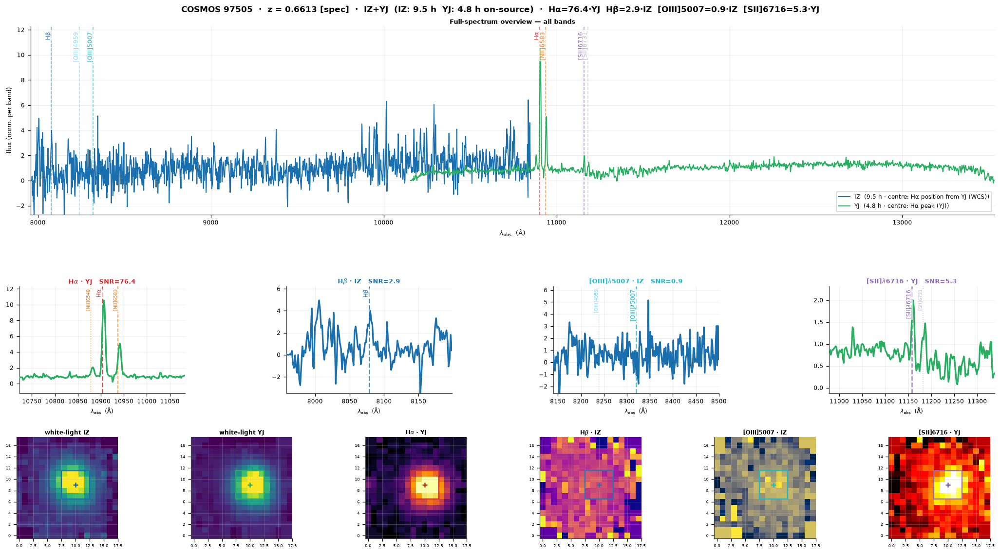

Saved → kmos_stacked_group_detail_COSMOS_97505.pdf


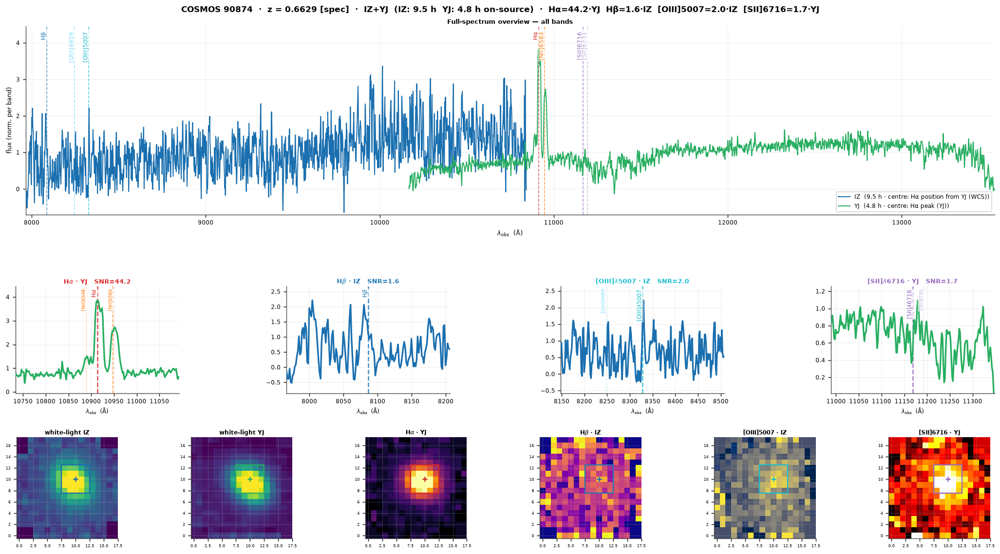

Saved → kmos_stacked_group_detail_COSMOS_90874.pdf


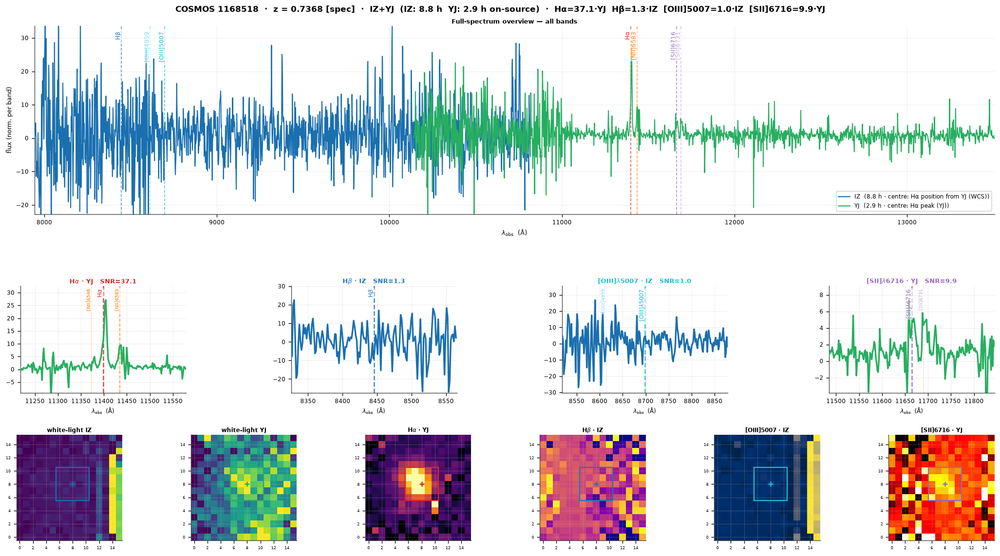

Saved → kmos_stacked_group_detail_COSMOS_1168518.pdf


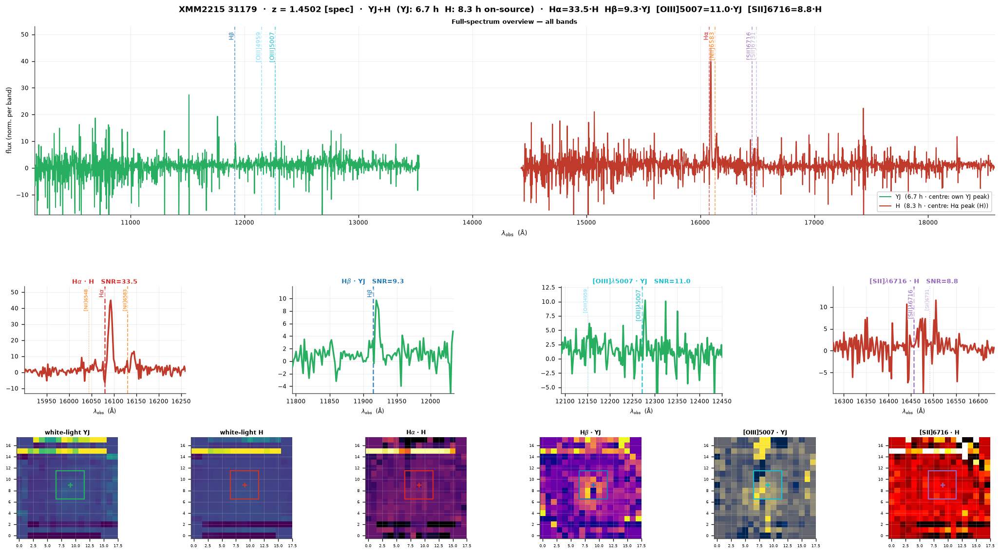

Saved → kmos_stacked_group_detail_XMM2215_31179.pdf


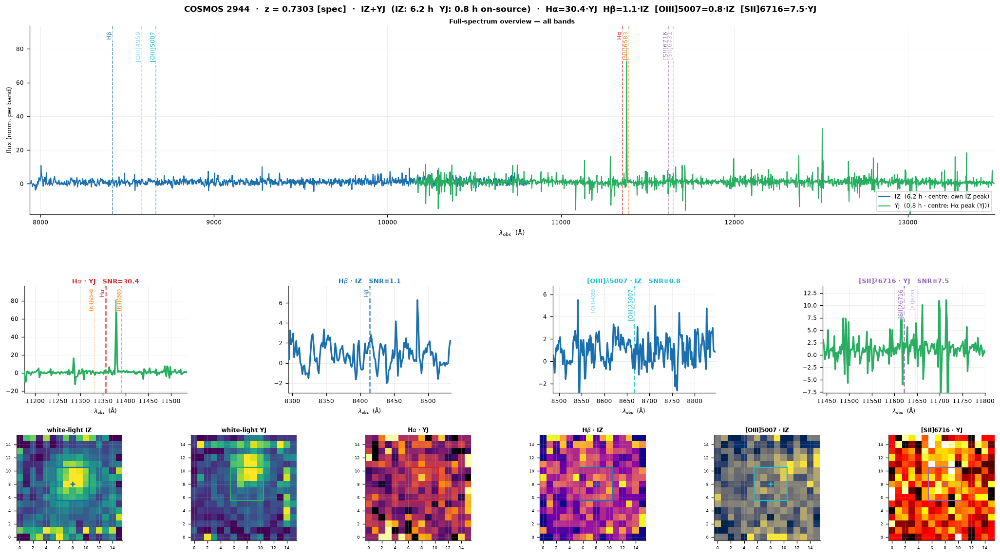

Saved → kmos_stacked_group_detail_COSMOS_2944.pdf


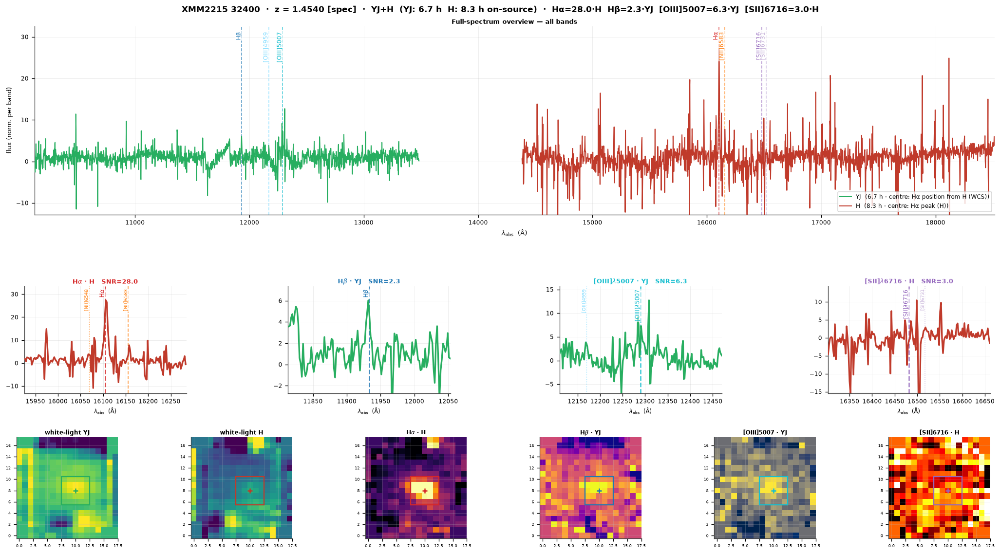

Saved → kmos_stacked_group_detail_XMM2215_32400.pdf


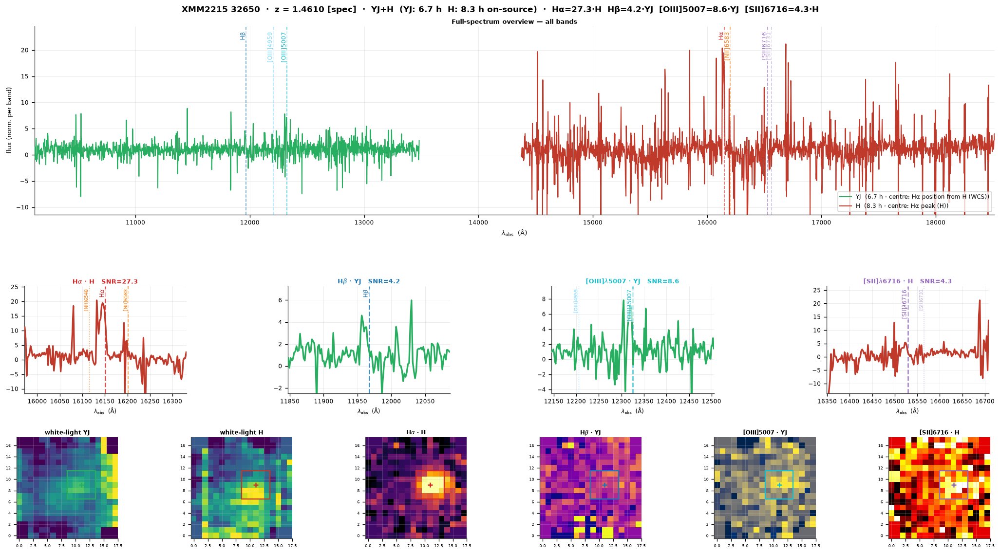

Saved → kmos_stacked_group_detail_XMM2215_32650.pdf


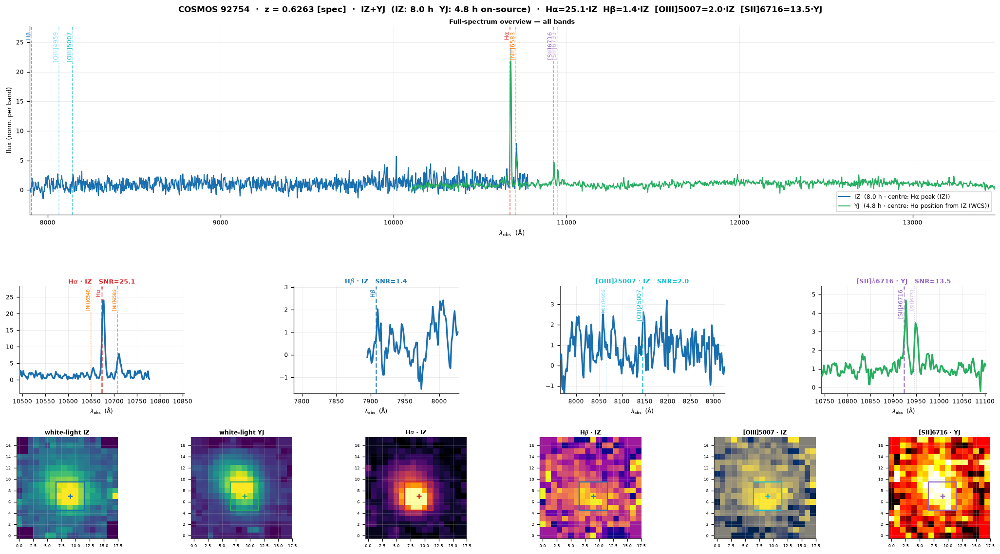

Saved → kmos_stacked_group_detail_COSMOS_92754.pdf


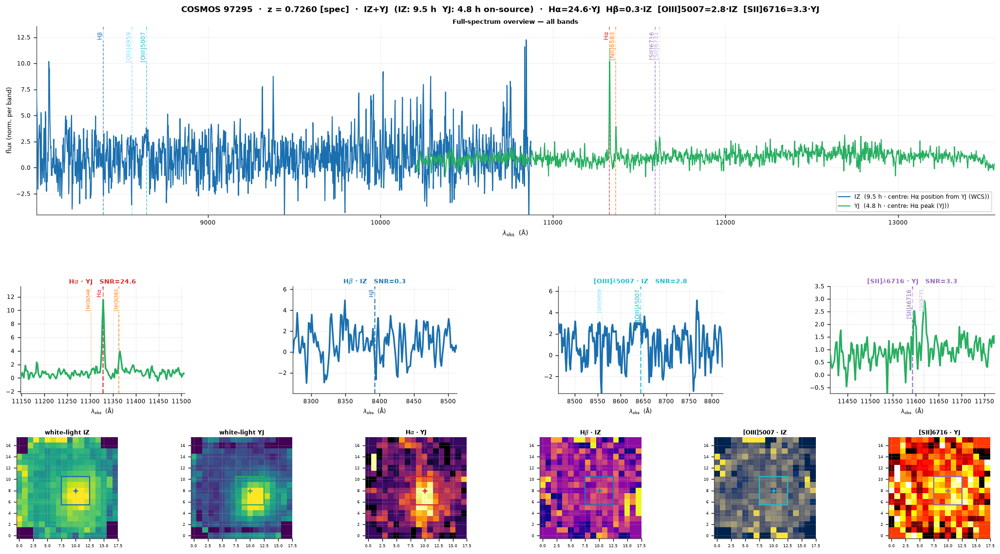

Saved → kmos_stacked_group_detail_COSMOS_97295.pdf


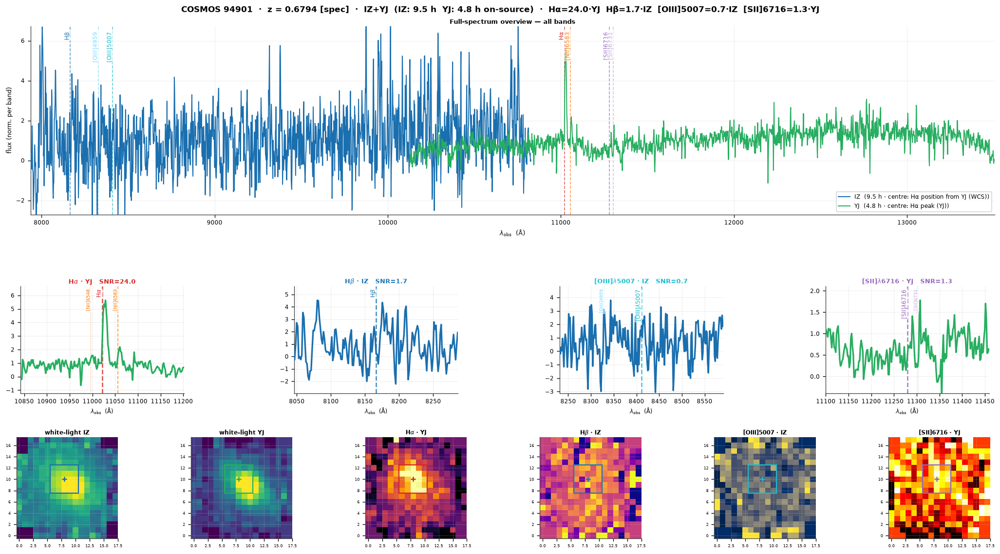

Saved → kmos_stacked_group_detail_COSMOS_94901.pdf


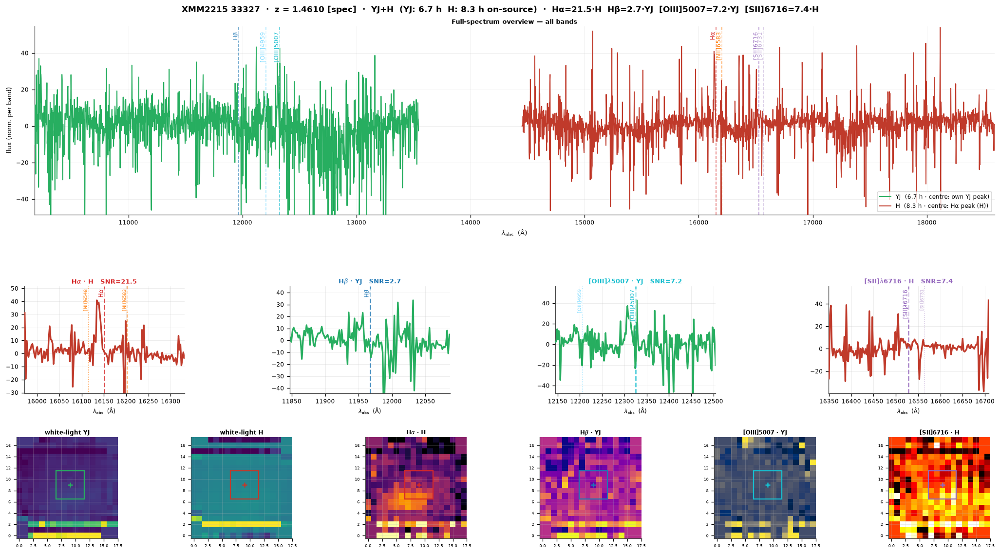

Saved → kmos_stacked_group_detail_XMM2215_33327.pdf


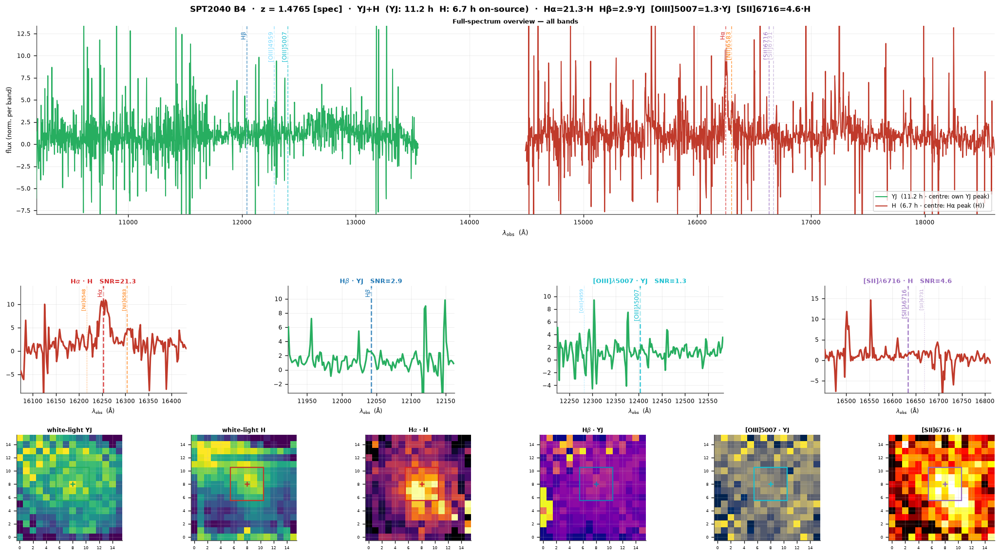

Saved → kmos_stacked_group_detail_SPT2040_B4.pdf


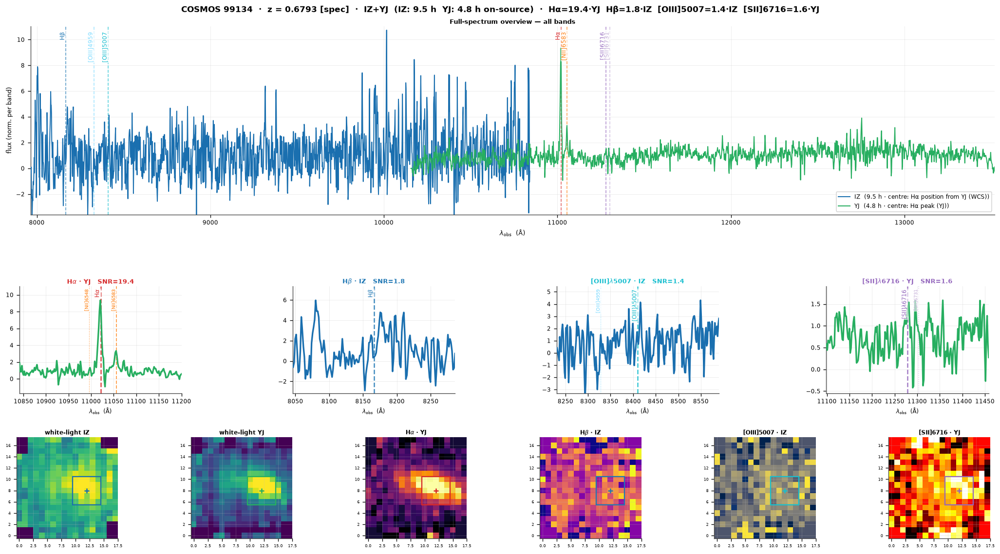

Saved → kmos_stacked_group_detail_COSMOS_99134.pdf


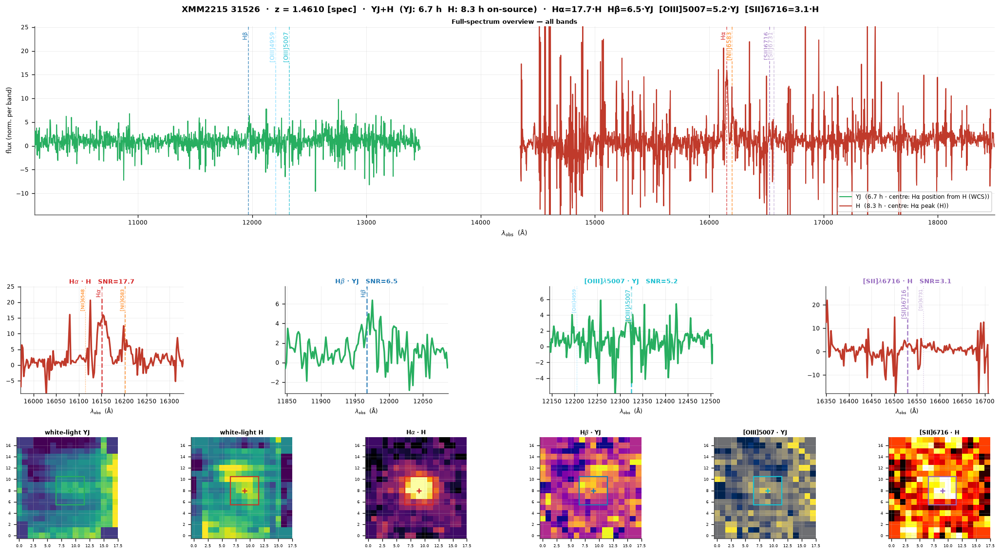

Saved → kmos_stacked_group_detail_XMM2215_31526.pdf


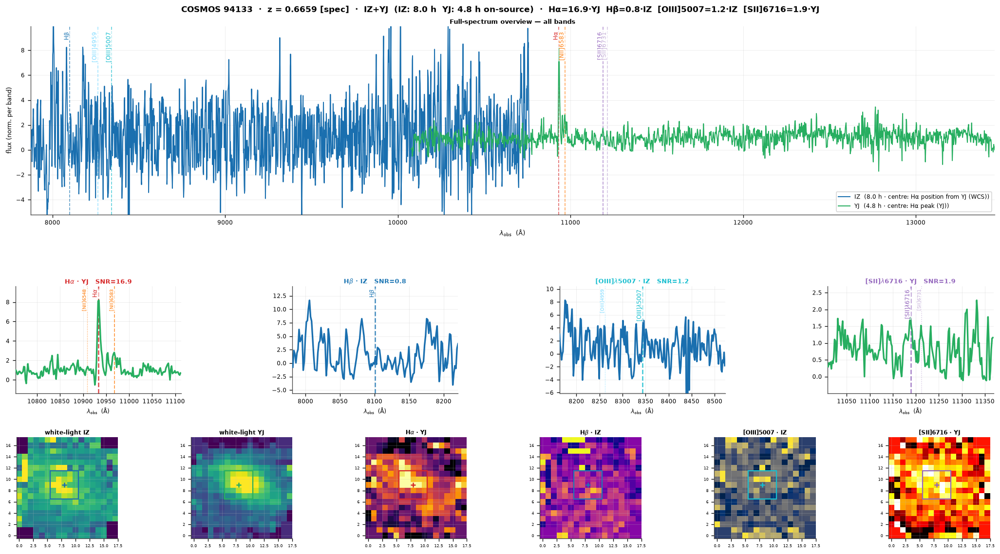

Saved → kmos_stacked_group_detail_COSMOS_94133.pdf


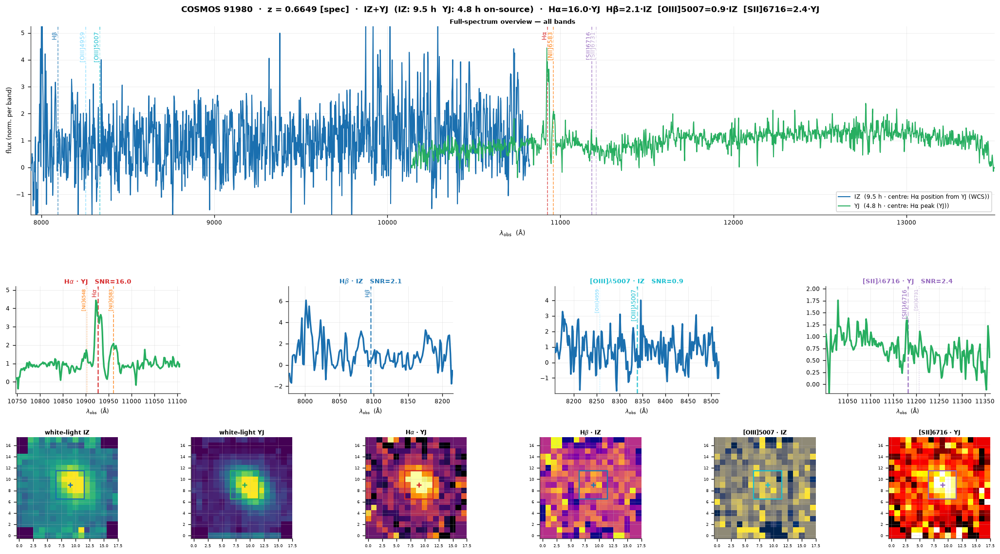

Saved → kmos_stacked_group_detail_COSMOS_91980.pdf


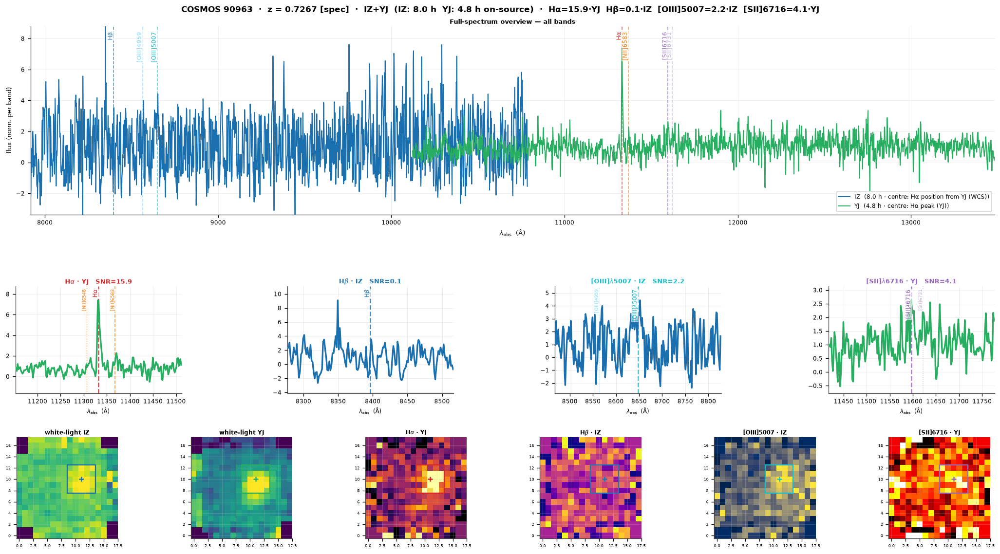

Saved → kmos_stacked_group_detail_COSMOS_90963.pdf


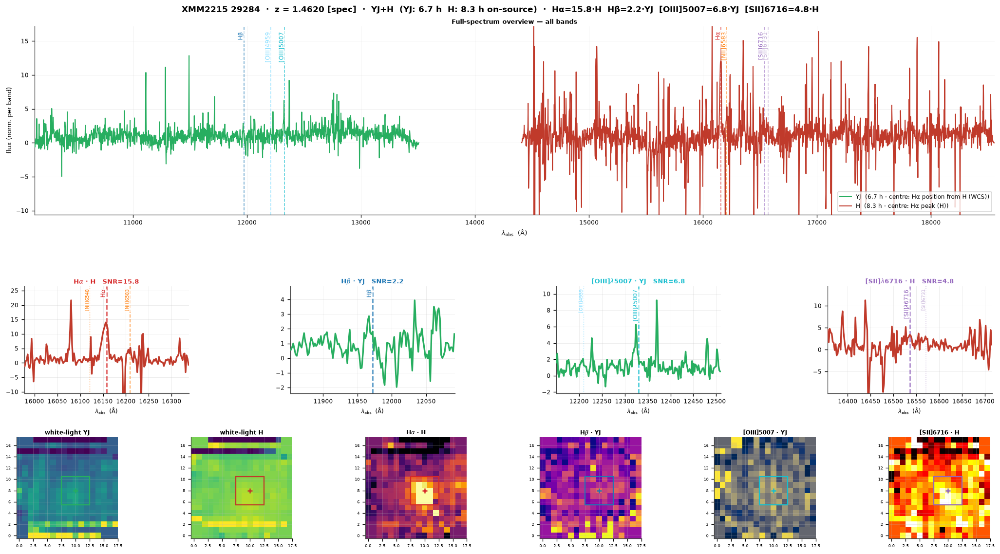

Saved → kmos_stacked_group_detail_XMM2215_29284.pdf


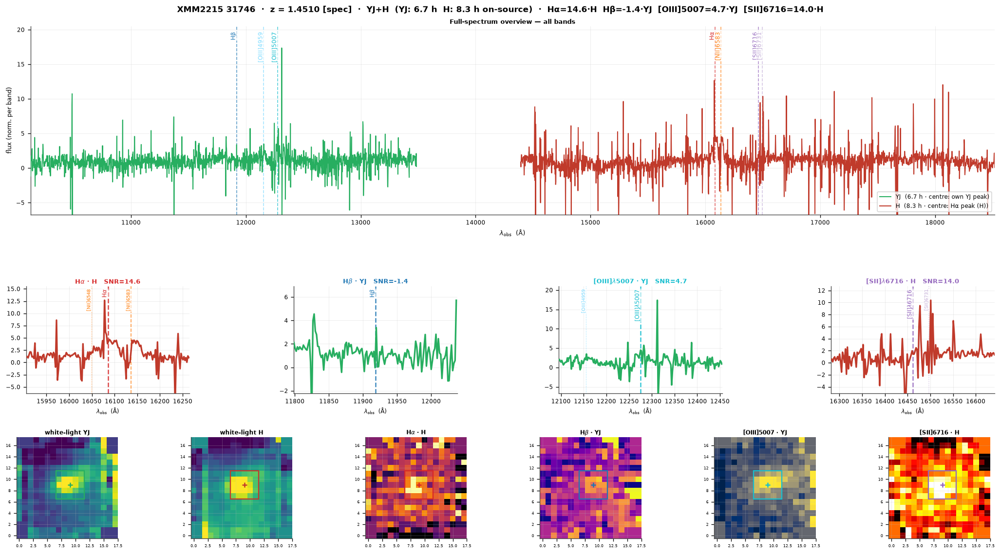

Saved → kmos_stacked_group_detail_XMM2215_31746.pdf


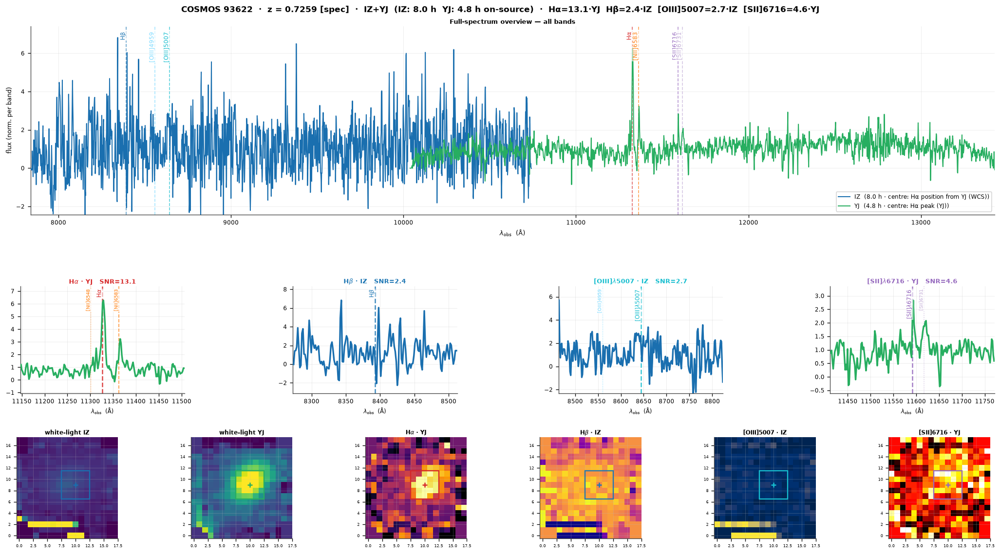

Saved → kmos_stacked_group_detail_COSMOS_93622.pdf


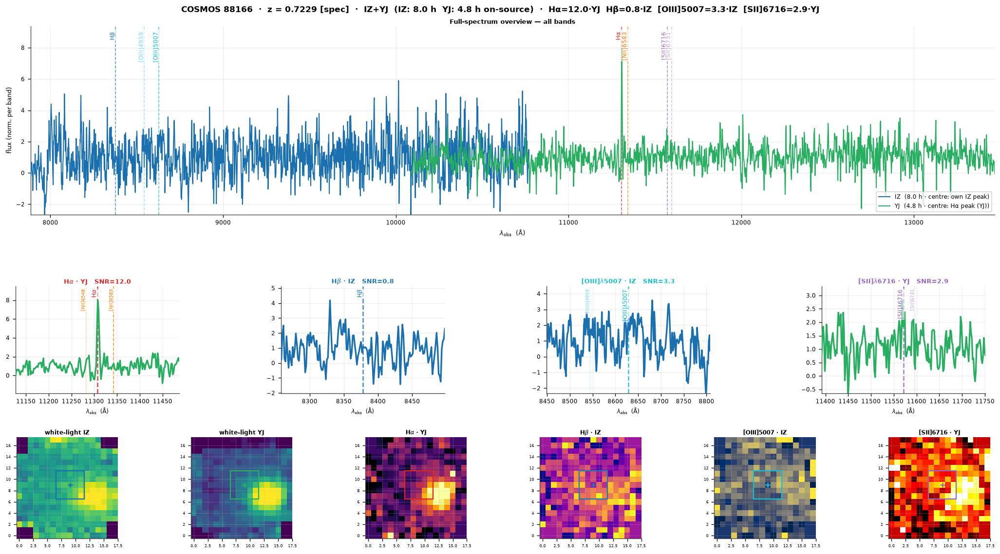

Saved → kmos_stacked_group_detail_COSMOS_88166.pdf


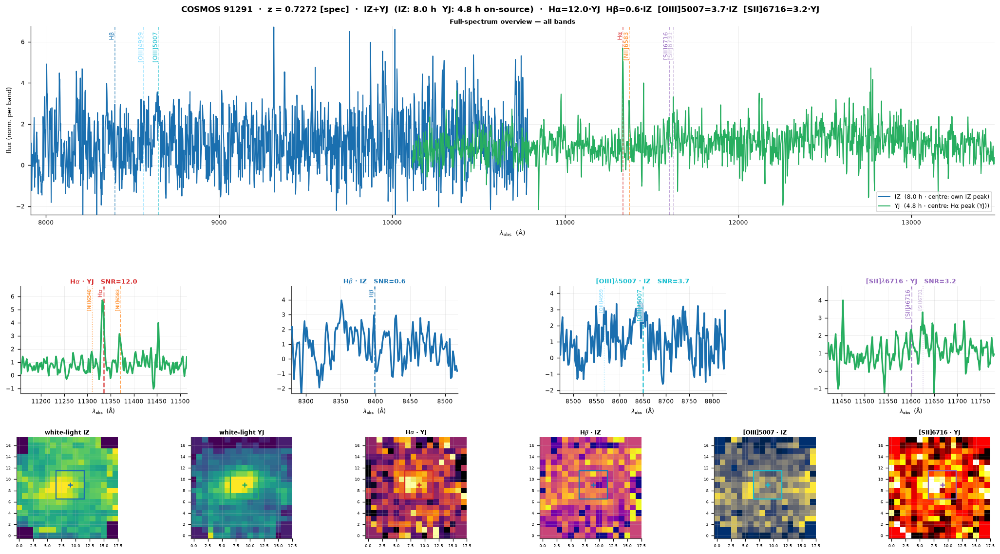

Saved → kmos_stacked_group_detail_COSMOS_91291.pdf


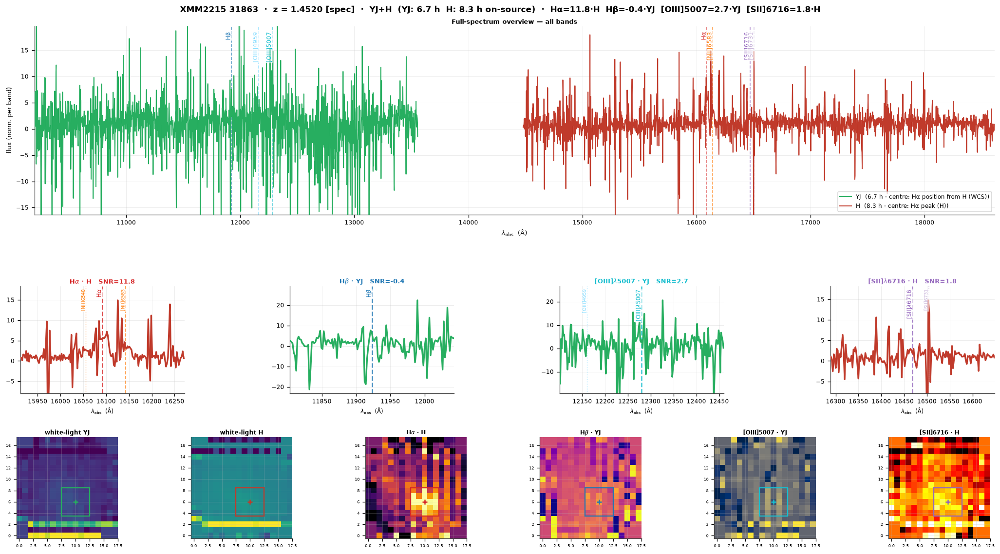

Saved → kmos_stacked_group_detail_XMM2215_31863.pdf


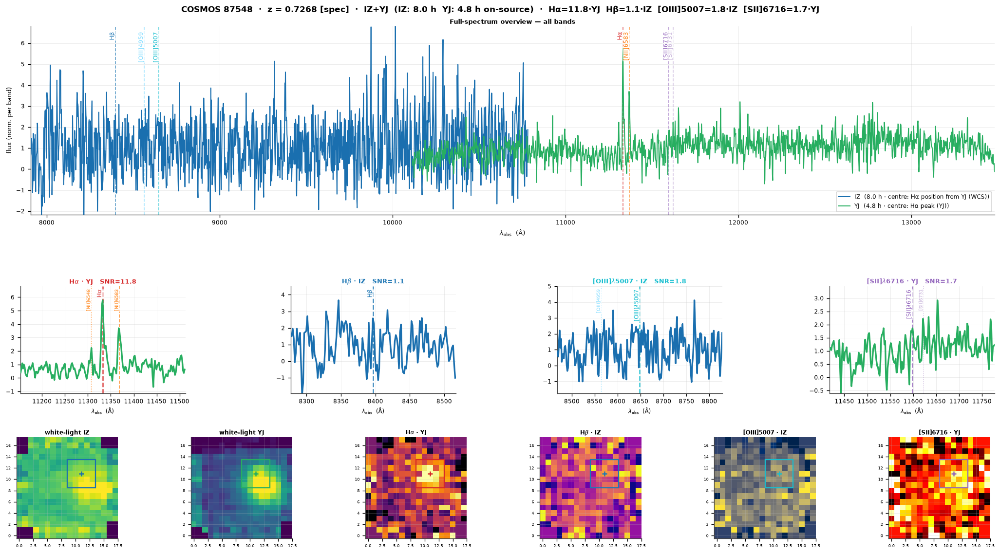

Saved → kmos_stacked_group_detail_COSMOS_87548.pdf


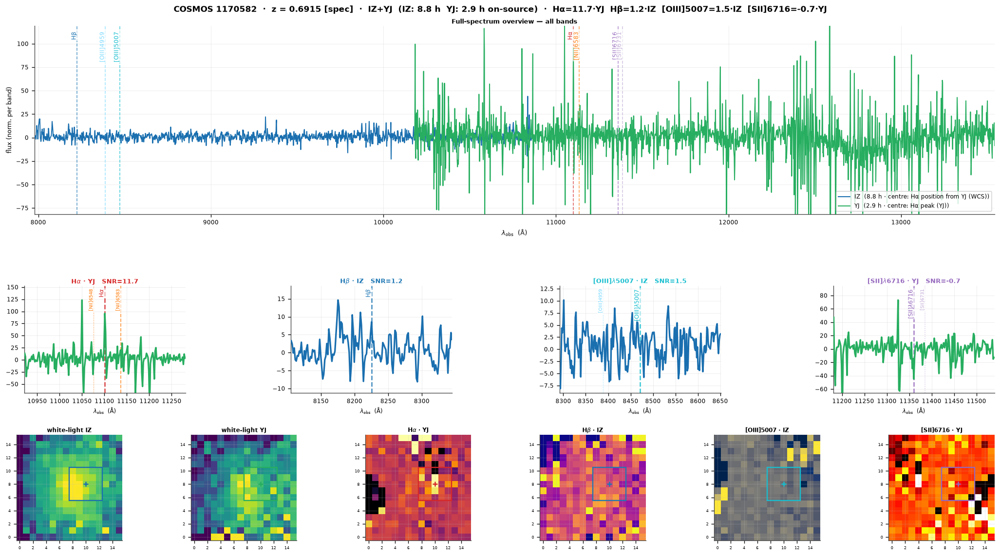

Saved → kmos_stacked_group_detail_COSMOS_1170582.pdf


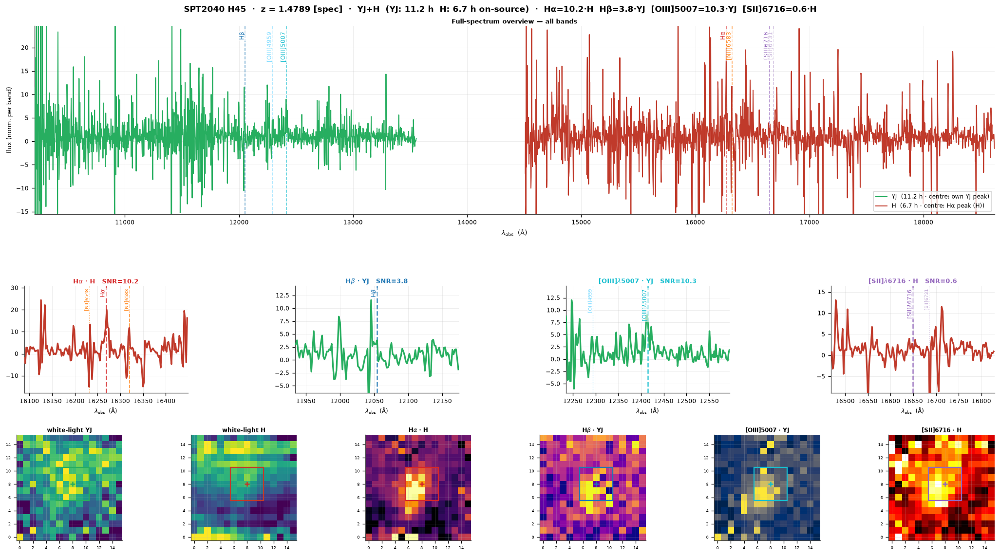

Saved → kmos_stacked_group_detail_SPT2040_H45.pdf


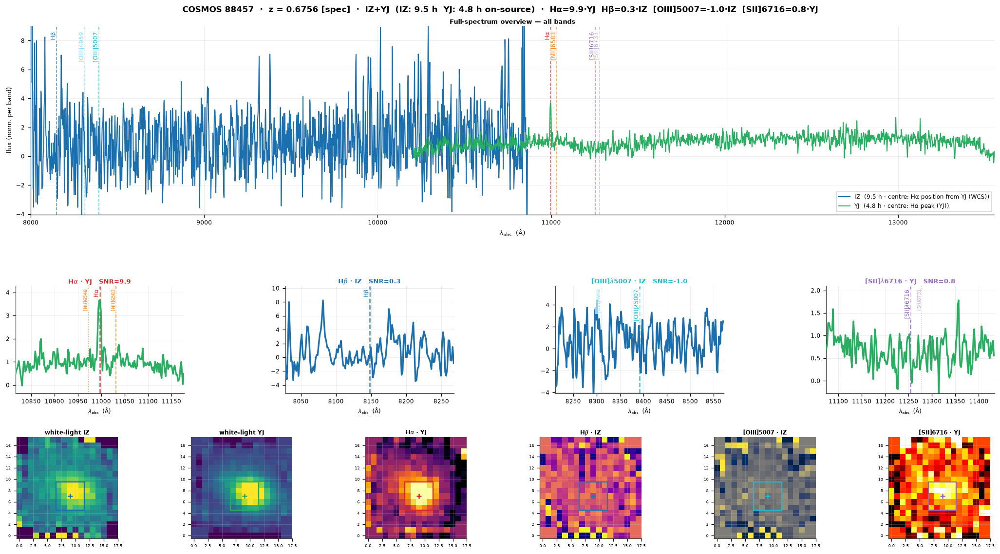

Saved → kmos_stacked_group_detail_COSMOS_88457.pdf


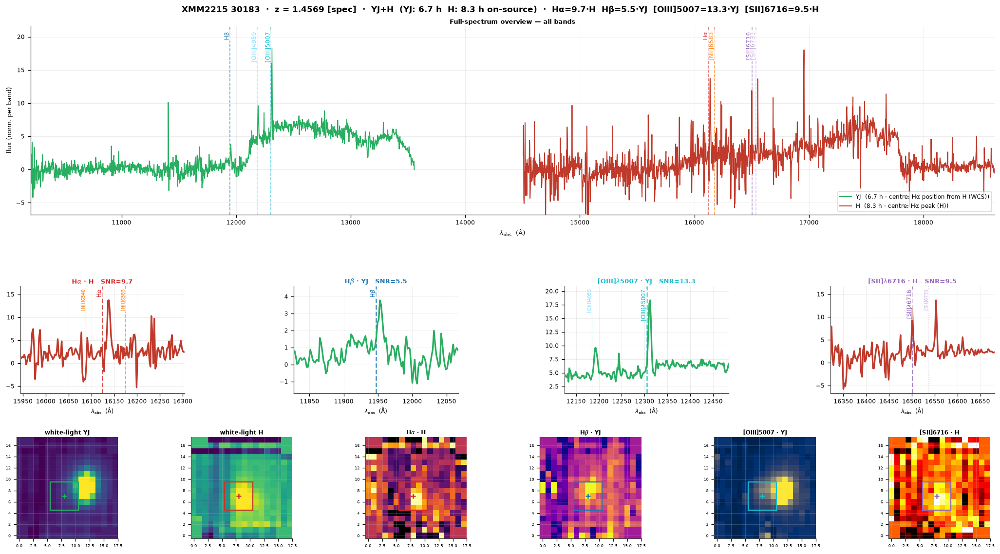

Saved → kmos_stacked_group_detail_XMM2215_30183.pdf


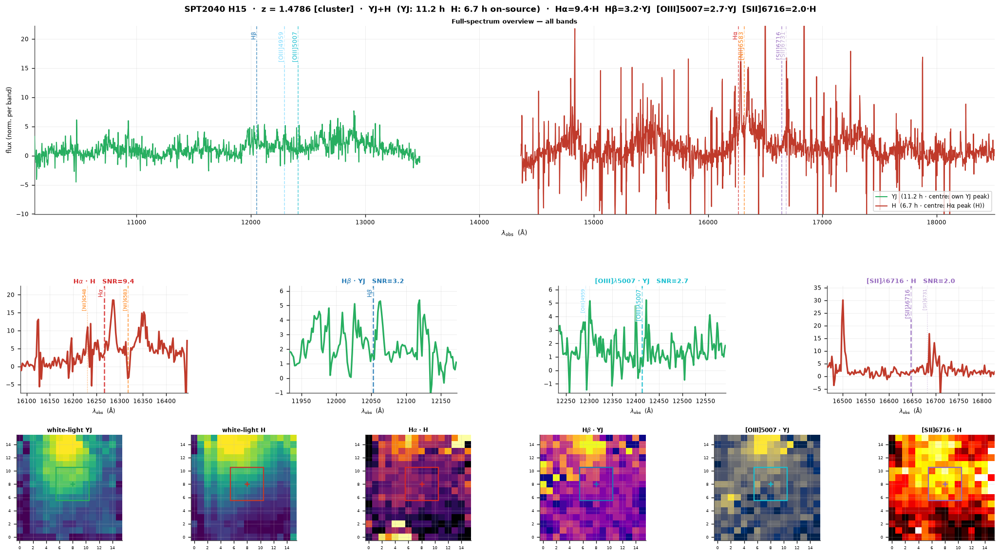

Saved → kmos_stacked_group_detail_SPT2040_H15.pdf


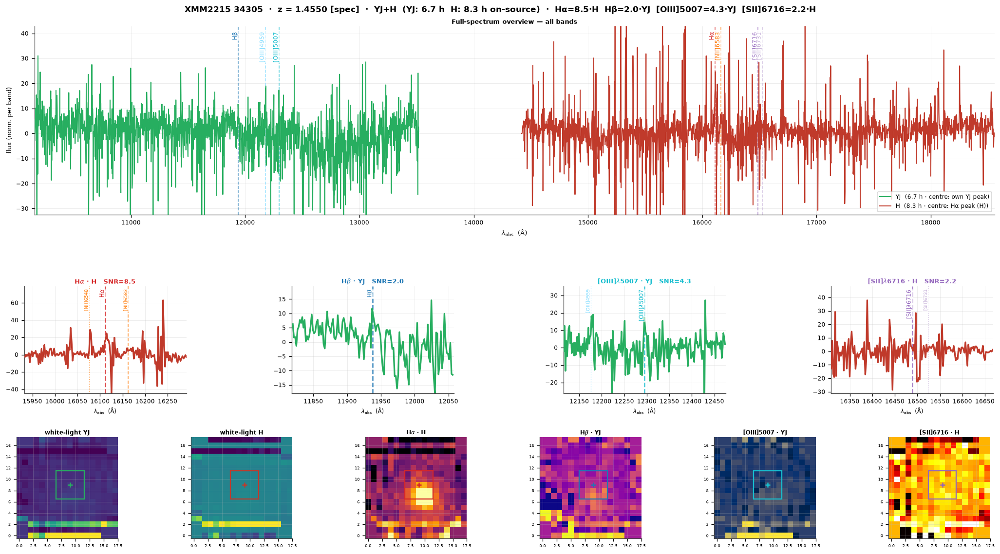

Saved → kmos_stacked_group_detail_XMM2215_34305.pdf


In [9]:
from matplotlib.patches import Rectangle

def _apt_rect(cy, cx, box=APERTURE, **kw):
    h2 = box // 2
    return Rectangle((cx - h2 - 0.5, cy - h2 - 0.5), box, box, linewidth=1.4, fill=False, **kw)

MAP_LINES = [  # (key, label, rest, marker colour, cmap)
    ('ha',   r'H$\alpha$',  HA_REST, '#d62728', 'inferno'),
    ('hb',   r'H$\beta$',   0.48627, '#1f77b4', 'plasma'),
    ('oiii', '[OIII]5007',  0.50082, '#17becf', 'cividis'),
    ('sii',  '[SII]6716',   0.67163, '#9467bd', 'hot'),
]

def _show_map(ax, im, title, m, ec, cmap):
    if im is None or not np.isfinite(im).any():
        ax.text(0.5, 0.5, 'not covered', ha='center', va='center', transform=ax.transAxes,
                fontsize=7, color='#aaa', style='italic')
    else:
        fin = im[np.isfinite(im)]
        ax.imshow(im, origin='lower', aspect='equal', cmap=cmap,
                  vmin=np.nanpercentile(fin, 5), vmax=np.nanpercentile(fin, 97))
        cy, cx = m['ctr_ha']
        ax.plot(cx, cy, '+', ms=6, mew=1.5, color=ec, zorder=5)
        ax.add_patch(_apt_rect(cy, cx, edgecolor=ec, zorder=5))
    ax.set_title(title, fontsize=7, pad=3)
    ax.tick_params(labelsize=5)

top_groups = [g for g in gal_groups if g['z_type'] in ('spec', 'cluster')
              and g['best'] >= SNR_MIN][:TOP_DETAIL]

for g, color in zip(top_groups, PALETTE * 10):
    z, members = g['z'], g['members']
    _plain = {'ha': 'Hα', 'hb': 'Hβ', 'oiii': '[OIII]5007', 'sii': '[SII]6716'}
    snr_txt = "  ".join(f"{_plain[k]}={g['snr'][k]:.1f}·{g['use'][k]['band']}"
                        for k, *_ in ZOOM_PANELS
                        if g['use'][k] is not None and np.isfinite(g['snr'][k]))
    times = "  ".join(f"{m['band']}: {m.get('exptime_s', np.nan)/3600:.1f} h" for m in members)
    fig = plt.figure(figsize=(17, 9.5), constrained_layout=True)
    fig.suptitle(f"{g['field']} {g['tid']}  ·  z = {z:.4f} [{g['z_type']}]  ·  "
                 f"{'+'.join(m['band'] for m in members)}  ({times} on-source)  ·  {snr_txt}",
                 fontsize=10, fontweight='bold')
    outer = gridspec.GridSpec(3, 1, figure=fig, height_ratios=[2.0, 1.5, 1.5], hspace=0.42)

    # ── Row 0: all bands on one wavelength axis ────────────────────────────────
    ax_full = fig.add_subplot(outer[0])
    lo_all, hi_all, ymin_l, ymax_l = np.inf, -np.inf, [], []
    for m in members:
        w, s = m['wave'], m['med']
        v = np.isfinite(w) & np.isfinite(s)
        if not v.any():
            continue
        ax_full.plot(w[v] * 1e4, s[v], color=BAND_COLORS.get(m['band'], color), lw=1.2, zorder=3,
                     label=f"{m['band']}  ({m.get('exptime_s', np.nan)/3600:.1f} h · centre: {m['ctr_src']})")
        lo_all, hi_all = min(lo_all, w[v].min()), max(hi_all, w[v].max())
        ymin_l.append(np.nanpercentile(s[v], 2))
        for k, lrest, *_ in ZOOM_PANELS:          # line peaks set the y-range
            lam = lrest * (1 + z)
            win = v & (np.abs(w - lam) < 0.004)
            if win.any() and np.isfinite(m.get(f'snr_{k}', np.nan)) and m[f'snr_{k}'] >= SNR_MIN:
                ymax_l.append(np.nanmax(s[win]))
        ymax_l.append(np.nanpercentile(s[v], 99))
    if ymin_l:
        ymin, ymax = min(ymin_l), max(ymax_l)
        ax_full.set_ylim(ymin - 0.15 * (ymax - ymin), ymax + 0.15 * (ymax - ymin))
    for lname, (lrest, lc) in EMISSION_LINES.items():
        lam = lrest * (1 + z)
        if lo_all <= lam <= hi_all and any(m['wave'].min() <= lam <= m['wave'].max() for m in members):
            ax_full.axvline(lam * 1e4, color=lc, lw=1.0, ls='--', alpha=0.7)
            ax_full.text(lam * 1e4, 0.97, lname, transform=ax_full.get_xaxis_transform(),
                         rotation=90, ha='right', va='top', fontsize=7, color=lc,
                         bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
    ax_full.set_xlim(lo_all * 1e4, hi_all * 1e4)
    ax_full.set_xlabel(r'$\lambda_{\rm obs}$  (Å)', fontsize=8)
    ax_full.set_ylabel('flux (norm. per band)', fontsize=8)
    ax_full.set_title('Full-spectrum overview — all bands', fontsize=8, pad=3)
    ax_full.tick_params(labelsize=7)
    ax_full.legend(fontsize=7, loc='lower right', framealpha=0.8)

    # ── Row 1: line zooms from the matching band ───────────────────────────────
    inner_zoom = gridspec.GridSpecFromSubplotSpec(1, len(ZOOM_PANELS), subplot_spec=outer[1], wspace=0.35)
    for ci, (lkey, lrest, label, lc, zhalf, companions) in enumerate(ZOOM_PANELS):
        ax = fig.add_subplot(inner_zoom[ci])
        m = g['use'][lkey]
        lam = lrest * (1 + z); wlo, whi = lam - zhalf, lam + zhalf
        if m is None:
            ax.text(0.5, 0.5, 'not covered by any band', ha='center', va='center',
                    transform=ax.transAxes, fontsize=8, color='#aaa', style='italic')
            ax.set_title(label, fontsize=8, color=lc, pad=3)
            continue
        w = m['wave']; mask = (w >= wlo) & (w <= whi)
        ax.plot(w[mask] * 1e4, m['med'][mask], color=BAND_COLORS.get(m['band'], color), lw=2.0, zorder=3)
        ax.axvline(lam * 1e4, color=lc, lw=1.5, ls='--', alpha=0.85, zorder=2)
        ax.text(lam * 1e4, 0.97, label, transform=ax.get_xaxis_transform(), rotation=90,
                ha='right', va='top', fontsize=7, color=lc, bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
        for cname, crest, clc, clw, cls in companions:
            co = crest * (1 + z)
            if wlo <= co <= whi:
                ax.axvline(co * 1e4, color=clc, lw=clw, ls=cls, alpha=0.75, zorder=2)
                ax.text(co * 1e4, 0.97, cname, transform=ax.get_xaxis_transform(), rotation=90,
                        ha='right', va='top', fontsize=6, color=clc,
                        bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
        fv = m['med'][mask]; fv = fv[np.isfinite(fv)]
        if fv.size:
            ylo, yhi = np.nanpercentile(fv, 2), np.nanmax(fv)
            pad = 0.18 * max(yhi - ylo, 0)
            ax.set_ylim(ylo - pad, yhi + pad)
        ax.set_xlim(wlo * 1e4, whi * 1e4)
        ax.tick_params(labelsize=7)
        ax.set_xlabel(r'$\lambda_{\rm obs}$  (Å)', fontsize=7)
        snr_v = m.get(f'snr_{lkey}', np.nan)
        ax.set_title(f"{label} · {m['band']}   " + (f"SNR={snr_v:.1f}" if np.isfinite(snr_v) else "SNR=—"),
                     fontsize=8, color=lc, pad=3)

    # ── Row 2: white-light of every band + line maps from the matching band ───
    n_maps = len(members) + len(MAP_LINES)
    inner_maps = gridspec.GridSpecFromSubplotSpec(1, n_maps, subplot_spec=outer[2], wspace=0.35)
    for mi, m in enumerate(members):
        cube = m['cube']
        valid = _erode_valid(np.isfinite(cube), EDGE_MARGIN)
        wl = np.nansum(np.where(valid, cube, np.nan), axis=0)
        _show_map(fig.add_subplot(inner_maps[mi]), wl, f"white-light {m['band']}", m,
                  BAND_COLORS.get(m['band'], 'red'), 'viridis')
    for j, (k, mlabel, mrest, ec, cmap) in enumerate(MAP_LINES):
        m = g['use'][k]
        im = narrowband_image(m['cube'], m['wave'], z, mrest) if m is not None else None
        _show_map(fig.add_subplot(inner_maps[len(members) + j]), im,
                  f"{mlabel} · {m['band']}" if m is not None else mlabel, m, ec, cmap)

    fname = f"kmos_stacked_group_detail_{g['field']}_{g['tid']}.pdf"
    plt.savefig(fname, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")